# Egocentric Hand Visibility — Detector Rate vs Reviewed Visibility
Companion notebook to **Origin Data Lab Technical Field Note #07**.

This notebook loads the per-frame hand-detection table for three egocentric recordings (7,557 frames), runs quality checks, recomputes every headline number, and visualises how far a single hand-detector pass is from the visibility seen in an independent review.

> **Status:** AI-only preliminary. Detections come from MediaPipe Hands; the review labels come from an AI visual review (multimodal model), **not** from people. No human verification has been performed yet.

## 1. Load the data

In [1]:
import glob, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

def find(name):
    hits = glob.glob(f'/kaggle/input/**/{name}', recursive=True) + glob.glob(f'**/{name}', recursive=True)
    if not hits:
        raise FileNotFoundError(name)
    return hits[0]

frames = pd.read_csv(find('hand_visibility_frames.csv'))
review = pd.read_csv(find('ai_review_labels.csv'))
summary = pd.read_csv(find('recording_summary.csv'))
keysteps = pd.read_csv(find('keystep_summary.csv'))
print(frames.shape, review.shape)
frames.head()

(7557, 37) (120, 6)


,recording,frame,time_s,single_L,single_score_L,single_cx_L,single_cy_L,single_x0_L,single_x1_L,single_y0_L,...,single_both,pass3_both,consensus_both,n_hands_single,n_hands_flip,n_hands_lite,passes_agree,flicker,blur_px_pred,rotation_dps
0,stereo_rig_left,0,0.0000,1,0.8654,0.5021,0.7051,0.4654,0.5225,0.6832,...,1,1,1,2,2,2,1,0,0.236,4.63
1,stereo_rig_left,1,0.0333,1,0.8654,0.5025,0.7038,0.4656,0.5220,0.6834,...,1,1,1,2,2,2,0,0,0.168,2.74
2,stereo_rig_left,2,0.0667,1,0.8511,0.5030,0.7040,0.4664,0.5214,0.6843,...,1,1,1,2,2,2,0,0,0.236,2.86
3,stereo_rig_left,3,0.1007,1,0.9231,0.5049,0.7052,0.4669,0.5251,0.6839,...,1,1,1,2,2,2,0,0,0.448,5.86
4,stereo_rig_left,4,0.1333,1,0.8694,0.5031,0.7032,0.4658,0.5271,0.6828,...,1,1,1,2,2,2,1,0,0.433,4.49


## 2. Column guide
| Column | Meaning |
|---|---|
| `single_L`, `single_R` | 1 if the single pass (MediaPipe full model, static-image mode) detected the wearer's left / right hand |
| `flip_*`, `lite_*` | Same, for the mirrored-input pass and the lite-model pass |
| `pass3_*` | 1 if any of the three passes detected the hand in this frame |
| `consensus_*` | 1 if `pass3_*` is 1 anywhere within ±2 frames |
| `single_cx_*`, `single_cy_*`, `single_x0_*` … | Normalised hand centre and landmark extent from the single pass |
| `passes_agree` | 1 if all three passes agree on which hands are present |
| `blur_px_pred` | Gyro-predicted motion blur (stereo rig only, Field Note #06) |
| `rotation_dps` | Camera rotation rate in °/s |
Review states: **F** fully in view, **C** cut by the image border, **N** not visible.

## 3. Quality checks

In [2]:
checks = {
    'frames per recording': frames.groupby('recording').size().to_dict(),
    'duplicate frame ids': int(frames.duplicated(['recording','frame']).sum()),
    'frame ids contiguous': bool(frames.groupby('recording').frame.apply(lambda f: (f.sort_values().diff().dropna()==1).all()).all()),
    'binary columns valid': bool(frames[[c for c in frames.columns if c.startswith(('single_L','single_R','flip_','lite_','pass3_','consensus_'))]].isin([0,1]).all().all()),
    'single <= pass3 <= consensus': bool(((frames.single_L<=frames.pass3_L)&(frames.pass3_L<=frames.consensus_L)&(frames.single_R<=frames.pass3_R)&(frames.pass3_R<=frames.consensus_R)).all()),
    'review frames exist in table': bool(review.merge(frames,on=['recording','frame']).shape[0]==len(review)),
    'review states valid': bool(review[['review_L','review_R']].isin(['F','C','N']).all().all()),
}
checks

{'frames per recording': {'phone_knife_prep': 1979,
  'phone_seasoning': 1978,
  'stereo_rig_left': 3600},
 'duplicate frame ids': 0,
 'frame ids contiguous': True,
 'binary columns valid': True,
 'single <= pass3 <= consensus': True,
 'review frames exist in table': True,
 'review states valid': True}

## 4. Recompute the consensus rule

In [3]:
WINDOW = 2
def consensus(d, side):
    p3 = ((d[f'single_{side}'] + d[f'flip_{side}'] + d[f'lite_{side}']) >= 1).astype(int)
    return p3.rolling(2*WINDOW+1, center=True, min_periods=1).max().astype(int)

ok = True
for rec, d in frames.groupby('recording'):
    d = d.sort_values('frame')
    for s in 'LR':
        ok &= bool((consensus(d, s).values == d[f'consensus_{s}'].values).all())
print('consensus column reproduced:', ok)

consensus column reproduced: True


## 5. Both-hands rate by method

In [4]:
def wilson(k, n, z=1.96):
    p = k/n; d = 1+z*z/n; c = (p+z*z/(2*n))/d; h = z*np.sqrt(p*(1-p)/n+z*z/(4*n*n))/d
    return c-h, c+h

rows = []
for rec, d in frames.groupby('recording', sort=False):
    r = review[review.recording==rec]
    vis = int(((r.review_L!='N')&(r.review_R!='N')).sum()); n = len(r)
    lo, hi = wilson(vis, n)
    rows.append(dict(recording=rec, single=d.single_both.mean(), pass3=d.pass3_both.mean(),
                     consensus=d.consensus_both.mean(), review=vis/n, review_ci=f'{lo:.3f}–{hi:.3f}'))
rates = pd.DataFrame(rows); rates.round(3)

,recording,single,pass3,consensus,review,review_ci
0,stereo_rig_left,0.581,0.827,0.953,1.000,0.912–1.000
1,phone_knife_prep,0.418,0.666,0.843,0.950,0.835–0.986
2,phone_seasoning,0.741,0.849,0.899,0.975,0.871–0.996


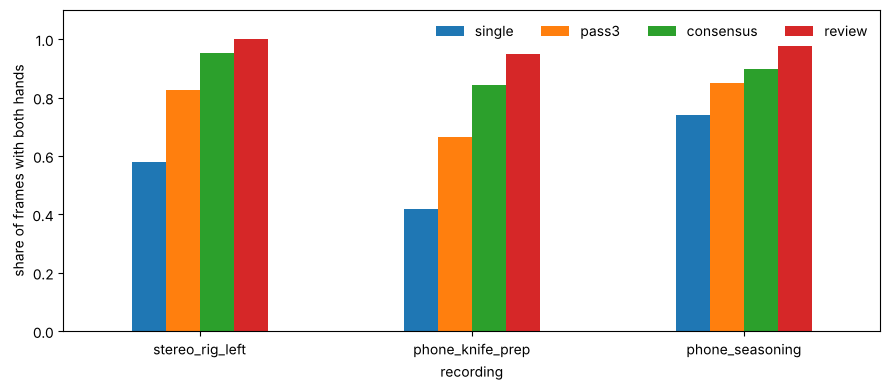

In [5]:
ax = rates.set_index('recording')[['single','pass3','consensus','review']].plot.bar(figsize=(9,4), rot=0)
ax.set_ylabel('share of frames with both hands'); ax.set_ylim(0,1.1); ax.legend(ncol=4, frameon=False)
plt.tight_layout(); plt.show()

## 6. Detector recall against the review

In [6]:
idx = frames.set_index(['recording','frame'])
rec_rows = []
for _, r in review.iterrows():
    for s in 'LR':
        if r[f'review_{s}'] != 'N':
            f = idx.loc[(r.recording, r.frame)]
            rec_rows.append(dict(recording=r.recording, single=f[f'single_{s}'], pass3=f[f'pass3_{s}'], consensus=f[f'consensus_{s}']))
recall = pd.DataFrame(rec_rows).groupby('recording').agg(visible_hands=('single','size'), single=('single','mean'), pass3=('pass3','mean'), consensus=('consensus','mean'))
recall.round(3)

,visible_hands,single,pass3,consensus
recording,,,,
phone_knife_prep,78,0.731,0.897,0.949
phone_seasoning,79,0.810,0.873,0.924
stereo_rig_left,80,0.800,0.925,0.988


## 7. Where hands appear in the frame

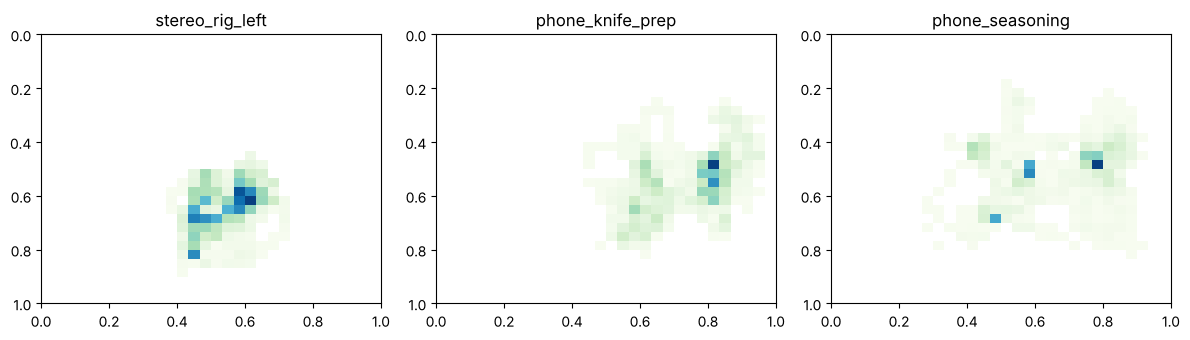

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(12,3.5))
for ax, (rec, d) in zip(axs, frames.groupby('recording', sort=False)):
    cx = pd.concat([d.single_cx_L, d.single_cx_R]).dropna(); cy = pd.concat([d.single_cy_L, d.single_cy_R]).dropna()
    ax.hist2d(cx, cy, bins=30, range=[[0,1],[0,1]], cmap='GnBu', cmin=1); ax.invert_yaxis(); ax.set_title(rec)
plt.tight_layout(); plt.show()

## 8. Detection vs motion

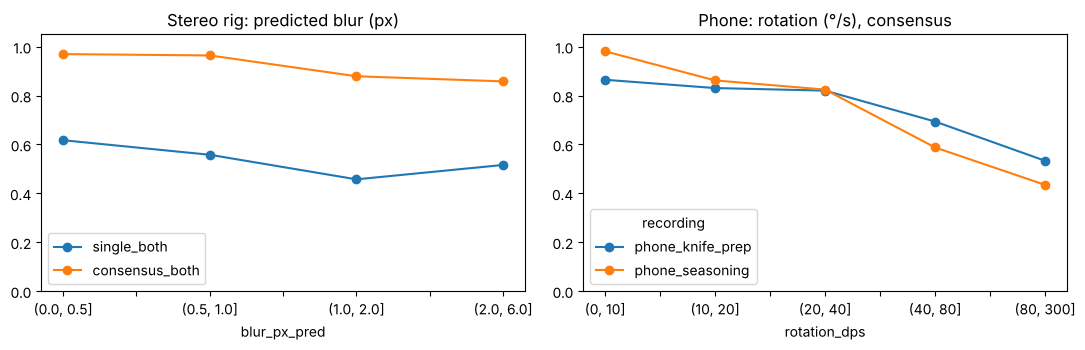

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11,3.6))
s1 = frames[frames.recording=='stereo_rig_left']
g = s1.groupby(pd.cut(s1.blur_px_pred, [0,0.5,1,2,6]), observed=True)[['single_both','consensus_both']].mean()
g.plot(ax=axs[0], marker='o', title='Stereo rig: predicted blur (px)'); axs[0].set_ylim(0,1.05)
ph = frames[frames.recording!='stereo_rig_left']
g = ph.groupby(['recording', pd.cut(ph.rotation_dps, [0,10,20,40,80,300])], observed=True).consensus_both.mean().unstack(0)
g.plot(ax=axs[1], marker='o', title='Phone: rotation (°/s), consensus'); axs[1].set_ylim(0,1.05)
plt.tight_layout(); plt.show()

## 9. Visibility by annotated keystep

In [9]:
keysteps.sort_values('consensus_both').head(8)

,recording,keystep_id,verb,frames,single_both,consensus_both
23,phone_seasoning,ks_B_11,place,75,0.0667,0.2000
9,phone_knife_prep,ks_A_10,non_task,36,0.0000,0.2778
7,phone_knife_prep,ks_A_08,place,60,0.0167,0.3333
20,phone_seasoning,ks_B_08,open,45,0.1111,0.4000
3,phone_knife_prep,ks_A_04,non_task,44,0.2045,0.5455
19,phone_seasoning,ks_B_07,place,54,0.3889,0.5741
5,phone_knife_prep,ks_A_06,place,135,0.1481,0.6000
17,phone_seasoning,ks_B_05,non_task,72,0.2361,0.6250


## 10. Interpretation
* A single detector pass is **not** a visibility measurement: on the head-mounted rig it found both hands in about 58% of frames, while every reviewed frame showed both hands.
* Three passes plus a ±2-frame window recover most misses, but the window was selected on the reviewed sample, so its recall is optimistic until checked on fresh frames.
* Border cuts appear in phone footage and not in the wide-angle rig sample; the detector itself rarely reports a cut hand, so cuts must be reviewed.
* False-positive rates cannot be estimated from this review (very few absent hands). A 416-frame human-verification sample has been designed but **not yet performed**; until then these are AI-only preliminary results.